<a href="https://colab.research.google.com/github/Josephjiao7/Geographic_moran_effect/blob/main/GME_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).



TWO-WAY WITHIN GME SYNTHETIC EXPERIMENT

Iterations: 6

True beta:
[ 1.   0.5 -0.5]

Estimated beta:
[ 1.02561056  0.49650937 -0.50538123]

Beta bias:
[ 0.02561056 -0.00349063 -0.00538123]

----------------------------------------------------------------------
Spatial loading recovery
----------------------------------------------------------------------
RMSE: 0.1201
MAE: 0.0958
R2: 0.9855
Corr: 0.9927

----------------------------------------------------------------------
Temporal factor recovery
----------------------------------------------------------------------
RMSE: 0.0394
MAE: 0.0330
R2: 0.9984
Corr: 0.9992

----------------------------------------------------------------------
Full GME recovery
----------------------------------------------------------------------
RMSE: 0.1234
MAE: 0.0831
R2: 0.9839
Corr: 0.9919

----------------------------------------------------------------------
MEI recovery
----------------------------------------------------------------------
RMSE: 0.07

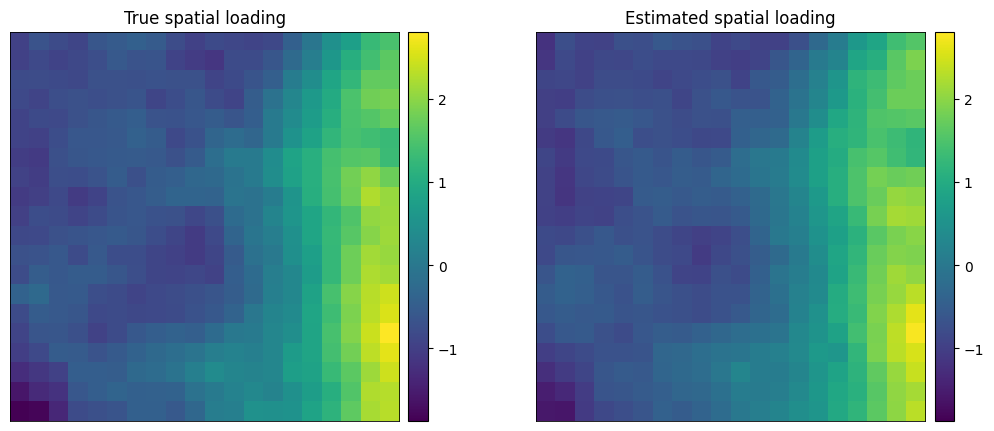

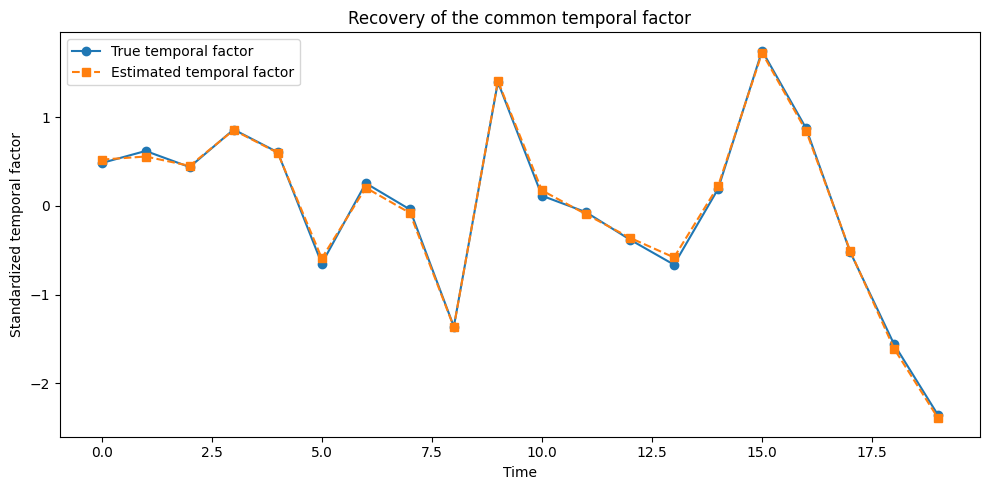

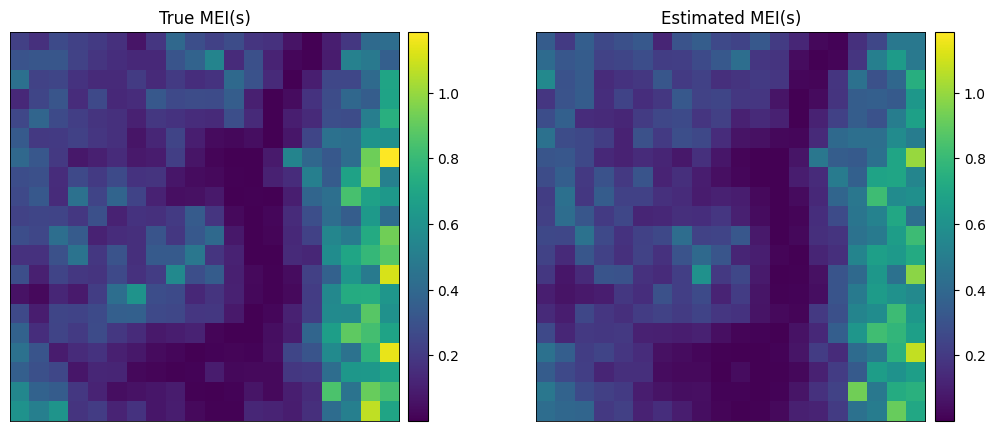

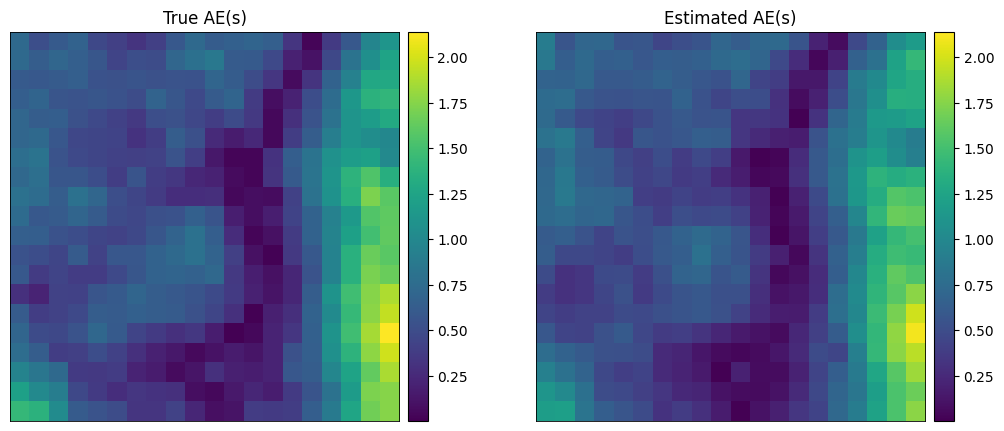


SUMMARY
Loading: RMSE=0.1201, MAE=0.0958, R2=0.9855, Corr=0.9927
Temporal factor: RMSE=0.0394, MAE=0.0330, R2=0.9984, Corr=0.9992
GME: RMSE=0.1234, MAE=0.0831, R2=0.9839, Corr=0.9919
MEI: RMSE=0.0726, MAE=0.0521, R2=0.8977, Corr=0.9484
AE: RMSE=0.0904, MAE=0.0720, R2=0.9539, Corr=0.9768


In [ ]:
"""
Geographic Moran Effect:
Two-Way Within Synchrony Factor Model

Simulation design
-----------------
The synthetic data contain:

1. A global temporal covariate:
       x_bar(t) ~ AR(p)

2. A spatially patterned local deviation:
       nu(s,t)

3. A local covariate:
       x(s,t) = x_bar(t) + nu(s,t)

4. A systematic regression component:
       X(s,t) beta

5. A global temporal effect:
       gamma * x_bar(t)

6. A Geographic Moran Effect:
       u(s,t) = a(s) * g(t)

7. Idiosyncratic noise.

Both x_bar(t) and x(s,t) enter the true data-generating
process, but only local covariates X(s,t) are supplied to
the fitted model.

Before estimation, both the outcome and the time-varying
covariates are transformed using a two-way within
transformation. This removes additive spatial and temporal
main effects before estimating the GME component.

The fitted model is:

    y_tilde(s,t)
        =
    X_tilde(s,t) beta
        +
    a(s) g(t)
        +
    epsilon(s,t)

Outputs
-------
- Spatial loading a(s)
- Common temporal factor g(t)
- Full GME u(s,t)
- Moran Effect Index MEI(s)
- Absolute Effect AE(s)
"""

import inspect
from dataclasses import dataclass
from typing import Tuple

import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt

from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score,
)


# ==========================================================
# 1. Conjugate Gradient solver wrapper
# ==========================================================

def cg_solve(
    A,
    b,
    atol=1e-10,
    rtol=1e-10,
    maxiter=5000,
):
    """
    SciPy-version-compatible conjugate-gradient solver.
    """

    sig = inspect.signature(
        spla.cg
    )

    params = sig.parameters

    if "rtol" in params:

        return spla.cg(
            A,
            b,
            atol=atol,
            rtol=rtol,
            maxiter=maxiter,
        )

    elif "tol" in params:

        return spla.cg(
            A,
            b,
            atol=atol,
            tol=rtol,
            maxiter=maxiter,
        )

    else:

        return spla.cg(
            A,
            b,
            maxiter=maxiter,
        )


# ==========================================================
# 2. Spatial graph utilities
# ==========================================================

def grid_adjacency(
    nr: int,
    nc: int,
    rook: bool = True,
) -> sp.csr_matrix:
    """
    Construct a regular lattice adjacency matrix.
    """

    n = nr * nc

    rows = []
    cols = []
    data = []

    def idx(r, c):
        return r * nc + c

    directions = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1),
    ]

    if not rook:

        directions += [
            (-1, -1),
            (-1, 1),
            (1, -1),
            (1, 1),
        ]

    for r in range(nr):

        for c in range(nc):

            i = idx(
                r,
                c,
            )

            for dr, dc in directions:

                rr = r + dr
                cc = c + dc

                if (
                    0 <= rr < nr
                    and
                    0 <= cc < nc
                ):

                    j = idx(
                        rr,
                        cc,
                    )

                    rows.append(
                        i
                    )

                    cols.append(
                        j
                    )

                    data.append(
                        1.0
                    )

    W = sp.coo_matrix(
        (
            data,
            (
                rows,
                cols,
            ),
        ),
        shape=(
            n,
            n,
        ),
    ).tocsr()

    W = (
        (W + W.T) > 0
    ).astype(
        float
    ).tocsr()

    W.setdiag(
        0.0
    )

    W.eliminate_zeros()

    return W


def row_standardize_W(
    W: sp.csr_matrix,
) -> sp.csr_matrix:
    """
    Row-standardize a spatial weights matrix.
    """

    W = W.tocsr()

    d = np.asarray(
        W.sum(
            axis=1
        )
    ).ravel()

    d_inv = np.zeros_like(
        d,
        dtype=float,
    )

    mask = (
        d > 0
    )

    d_inv[mask] = (
        1.0
        /
        d[mask]
    )

    return (
        sp.diags(
            d_inv,
            format="csr",
        )
        @ W
    ).tocsr()


def laplacian_from_W(
    W: sp.csr_matrix,
) -> sp.csr_matrix:
    """
    Graph Laplacian.
    """

    d = np.asarray(
        W.sum(
            axis=1
        )
    ).ravel()

    return (
        sp.diags(
            d,
            format="csr",
        )
        - W
    ).tocsr()


# ==========================================================
# 3. Temporal RW1 precision
# ==========================================================

def rw1_precision(
    T: int,
) -> np.ndarray:
    """
    First-order random-walk precision matrix.
    """

    D = np.zeros(
        (
            T - 1,
            T,
        )
    )

    for i in range(
        T - 1
    ):

        D[
            i,
            i,
        ] = -1.0

        D[
            i,
            i + 1,
        ] = 1.0

    return (
        D.T @ D
    )


# ==========================================================
# 4. AR processes
# ==========================================================

def simulate_ar1(
    T: int,
    phi: float,
    sigma: float,
    rng: np.random.Generator,
) -> np.ndarray:
    """
    Standardized AR(1) process.
    """

    g = np.zeros(
        T,
        dtype=float,
    )

    eps = rng.normal(
        0.0,
        sigma,
        size=T,
    )

    for t in range(
        1,
        T,
    ):

        g[t] = (
            phi
            * g[t - 1]
            + eps[t]
        )

    g = (
        g - g.mean()
    )

    g = (
        g
        /
        (
            g.std(
                ddof=1
            )
            + 1e-12
        )
    )

    return g


def simulate_ar_p(
    T: int,
    phi: tuple,
    sigma: float,
    rng: np.random.Generator,
    burnin: int = 200,
) -> np.ndarray:
    """
    General standardized AR(p) process.

    Example
    -------
    phi = (0.6, 0.2)
    """

    phi = np.asarray(
        phi,
        dtype=float,
    )

    p = len(
        phi
    )

    total_T = (
        T
        + burnin
        + p
    )

    x = np.zeros(
        total_T,
        dtype=float,
    )

    eps = rng.normal(
        0.0,
        sigma,
        size=total_T,
    )

    for t in range(
        p,
        total_T,
    ):

        past = x[
            t - p:t
        ][::-1]

        x[t] = (
            phi @ past
            + eps[t]
        )

    x = x[
        -T:
    ]

    x = (
        x - x.mean()
    )

    x = (
        x
        /
        (
            x.std(
                ddof=1
            )
            + 1e-12
        )
    )

    return x


# ==========================================================
# 5. Smooth spatial loading
# ==========================================================

def sample_smooth_a(
    L: sp.csr_matrix,
    tau_a: float,
    rng: np.random.Generator,
) -> np.ndarray:
    """
    Generate a smooth spatial loading field.
    """

    n = L.shape[0]

    jitter = 1e-6

    Q = (
        tau_a * L
        +
        jitter
        * sp.eye(
            n,
            format="csr",
        )
    ).tocsr()

    z = rng.normal(
        size=n
    )

    a, info = cg_solve(
        Q,
        z,
        atol=1e-10,
        rtol=1e-10,
        maxiter=5000,
    )

    if info != 0:

        a = spla.spsolve(
            Q.tocsc(),
            z,
        )

    # Geographic sensitivity is centered.
    a = (
        a - a.mean()
    )

    a = (
        a
        /
        (
            a.std(
                ddof=1
            )
            + 1e-12
        )
    )

    return a


# ==========================================================
# 6. Spatially patterned local disturbance
# ==========================================================

def simulate_spatial_patterned_nu(
    W: sp.csr_matrix,
    T: int,
    rho: float,
    rng: np.random.Generator,
) -> np.ndarray:
    """
    Generate spatially patterned local deviations:

        nu_t = (I - rho W)^(-1) e_t

    The process is generated independently at each time
    while retaining spatial dependence within each period.
    """

    W_row = row_standardize_W(
        W
    )

    n = W.shape[0]

    A = (
        sp.eye(
            n,
            format="csr",
        )
        -
        rho
        * W_row
    ).tocsc()

    solve_A = spla.factorized(
        A
    )

    nu = np.zeros(
        (
            n,
            T,
        ),
        dtype=float,
    )

    for t in range(
        T
    ):

        e = rng.normal(
            0.0,
            1.0,
            size=n,
        )

        nu[
            :,
            t,
        ] = solve_A(
            e
        )

    # Ensure that x_bar remains the common temporal part.
    nu = (
        nu
        -
        nu.mean(
            axis=0,
            keepdims=True,
        )
    )

    nu = (
        nu
        /
        (
            nu.std(
                ddof=1
            )
            + 1e-12
        )
    )

    return nu


# ==========================================================
# 7. Two-way within transformation
# ==========================================================

def two_way_within_y(
    y: np.ndarray,
) -> np.ndarray:
    """
    Two-way within transformation:

        y_tilde_st
        =
        y_st
        - y_bar_s.
        - y_bar_.t
        + y_bar_..
    """

    spatial_mean = y.mean(
        axis=1,
        keepdims=True,
    )

    temporal_mean = y.mean(
        axis=0,
        keepdims=True,
    )

    grand_mean = y.mean()

    return (
        y
        - spatial_mean
        - temporal_mean
        + grand_mean
    )


def two_way_within_X(
    X: np.ndarray,
) -> np.ndarray:
    """
    Apply the two-way within transformation separately
    to every time-varying covariate.
    """

    spatial_mean = X.mean(
        axis=1,
        keepdims=True,
    )

    temporal_mean = X.mean(
        axis=0,
        keepdims=True,
    )

    grand_mean = X.mean(
        axis=(
            0,
            1,
        ),
        keepdims=True,
    )

    return (
        X
        - spatial_mean
        - temporal_mean
        + grand_mean
    )


# ==========================================================
# 8. New synthetic data design
# ==========================================================

def simulate_data(
    nr: int = 20,
    nc: int = 20,
    T: int = 20,
    p: int = 3,
    phi_global: tuple = (0.6, 0.2),
    phi_g: float = 0.7,
    rho_nu: float = 0.6,
    nu_scale: float = 0.8,
    beta_local: float = 1.0,
    gamma_global: float = 1.5,
    sigma_eps: float = 1.0,
    tau_a: float = 5.0,
    seed: int = 42,
) -> Tuple[
    np.ndarray,
    np.ndarray,
    np.ndarray,
    np.ndarray,
    np.ndarray,
    np.ndarray,
    sp.csr_matrix,
]:
    """
    New synthetic DGP.

    Global temporal process:
        x_bar_t ~ AR(p)

    Spatial local deviation:
        nu_st

    Local covariate:
        x_st = x_bar_t + nu_st

    True outcome:
        y_st
        =
        X_st beta
        +
        gamma x_bar_t
        +
        a_s g_t
        +
        epsilon_st

    IMPORTANT
    ---------
    x_bar_t enters the true DGP but is NOT supplied
    to the fitted model.

    Returns
    -------
    y          : (n, T)
    X          : (n, T, p)
    beta_true  : (p,)
    a_true     : (n,)
    g_true     : (T,)
    x_bar      : (T,)
    W          : spatial adjacency matrix
    """

    rng = np.random.default_rng(
        seed
    )

    n = (
        nr * nc
    )

    # ------------------------------------------------------
    # Spatial graph
    # ------------------------------------------------------

    W = grid_adjacency(
        nr,
        nc,
        rook=True,
    )

    L = laplacian_from_W(
        W
    )

    # ------------------------------------------------------
    # Global temporal covariate
    # ------------------------------------------------------

    x_bar = simulate_ar_p(
        T=T,
        phi=phi_global,
        sigma=1.0,
        rng=rng,
    )

    # ------------------------------------------------------
    # Spatially patterned local deviation
    # ------------------------------------------------------

    nu = simulate_spatial_patterned_nu(
        W=W,
        T=T,
        rho=rho_nu,
        rng=rng,
    )

    # ------------------------------------------------------
    # Local covariate:
    #
    # x_st = x_bar_t + nu_st
    # ------------------------------------------------------

    x_local = (
        x_bar[
            None,
            :
        ]
        +
        nu_scale
        * nu
    )

    # ------------------------------------------------------
    # Covariate tensor
    #
    # Only local variables are supplied to estimation.
    # ------------------------------------------------------

    X = np.zeros(
        (
            n,
            T,
            p,
        ),
        dtype=float,
    )

    X[
        :,
        :,
        0,
    ] = x_local

    # Additional local controls
    if p > 1:

        X[
            :,
            :,
            1:
        ] = rng.normal(
            0.0,
            1.0,
            size=(
                n,
                T,
                p - 1,
            ),
        )

    # ------------------------------------------------------
    # Regression coefficients
    # ------------------------------------------------------

    beta_true = np.zeros(
        p,
        dtype=float,
    )

    beta_true[0] = (
        beta_local
    )

    if p == 2:

        beta_true[1] = 0.5

    elif p >= 3:

        beta_true[1:] = np.linspace(
            0.5,
            -0.5,
            p - 1,
        )

    # ------------------------------------------------------
    # True common temporal factor g_t
    # ------------------------------------------------------

    g_true = simulate_ar1(
        T=T,
        phi=phi_g,
        sigma=1.0,
        rng=rng,
    )

    # ------------------------------------------------------
    # True spatial sensitivity a_s
    # ------------------------------------------------------

    a_true = sample_smooth_a(
        L=L,
        tau_a=tau_a,
        rng=rng,
    )

    # ------------------------------------------------------
    # True Geographic Moran Effect
    # ------------------------------------------------------

    u_true = np.outer(
        a_true,
        g_true,
    )

    # ------------------------------------------------------
    # Local systematic component
    # ------------------------------------------------------

    local_effect = np.einsum(
        "ntp,p->nt",
        X,
        beta_true,
    )

    # ------------------------------------------------------
    # Global temporal main effect
    #
    # Included in the DGP,
    # deliberately omitted from fitted X.
    # ------------------------------------------------------

    global_effect = (
        gamma_global
        * x_bar[
            None,
            :
        ]
    )

    # ------------------------------------------------------
    # Idiosyncratic error
    # ------------------------------------------------------

    eps = rng.normal(
        0.0,
        sigma_eps,
        size=(
            n,
            T,
        ),
    )

    # ------------------------------------------------------
    # Final outcome
    # ------------------------------------------------------

    y = (
        local_effect
        +
        global_effect
        +
        u_true
        +
        eps
    )

    return (
        y,
        X,
        beta_true,
        a_true,
        g_true,
        x_bar,
        W,
    )


# ==========================================================
# 9. Two-way within GME estimator
# ==========================================================

@dataclass
class FitResult:

    beta: np.ndarray
    a: np.ndarray
    g: np.ndarray
    u: np.ndarray
    resid: np.ndarray
    y_within: np.ndarray
    X_within: np.ndarray
    n_iter: int


def fit_synchrony_factor_model(
    y: np.ndarray,
    X: np.ndarray,
    W: sp.csr_matrix,
    lam_a: float = 10.0,
    lam_g: float = 10.0,
    ridge_beta: float = 1e-3,
    max_iter: int = 300,
    tol: float = 1e-7,
    seed: int = 0,
    cg_maxiter: int = 5000,
) -> FitResult:
    """
    Two-way within GME model.

    Step 1:
        Apply the two-way within transformation to y and X.

    Step 2:
        Estimate

            y_tilde
            =
            X_tilde beta
            +
            a g'
            +
            epsilon

        using alternating minimization.
    """

    rng = np.random.default_rng(
        seed
    )

    n, T = y.shape

    p = X.shape[2]

    # ------------------------------------------------------
    # Two-way within transformation
    # ------------------------------------------------------

    y_work = two_way_within_y(
        y
    )

    X_work = two_way_within_X(
        X
    )

    # ------------------------------------------------------
    # Spatial and temporal penalties
    # ------------------------------------------------------

    L = laplacian_from_W(
        W
    ).tocsr()

    Qt = rw1_precision(
        T
    )

    I_n = sp.eye(
        n,
        format="csr",
    )

    # ------------------------------------------------------
    # Initial regression fit
    # ------------------------------------------------------

    Xv = X_work.reshape(
        n * T,
        p,
    )

    Yv = y_work.reshape(
        n * T,
        1,
    )

    XtX = (
        Xv.T @ Xv
        +
        ridge_beta
        * np.eye(
            p
        )
    )

    beta = np.linalg.solve(
        XtX,
        Xv.T @ Yv,
    ).ravel()

    # ------------------------------------------------------
    # Initialization from residual SVD
    # ------------------------------------------------------

    R0 = (
        y_work
        -
        np.einsum(
            "ntp,p->nt",
            X_work,
            beta,
        )
    )

    U, singular_values, Vt = np.linalg.svd(
        R0,
        full_matrices=False,
    )

    g = Vt[
        0,
        :
    ].copy()

    g = (
        g - g.mean()
    )

    g = (
        g
        /
        (
            g.std(
                ddof=1
            )
            + 1e-12
        )
    )

    a = (
        R0 @ g
    ) / (
        np.sum(
            g ** 2
        )
        + 1e-12
    )

    # Center loading under two-way identification.
    a = (
        a - a.mean()
    )

    epsI_a = 1e-6
    epsI_g = 1e-8

    # ------------------------------------------------------
    # Alternating estimation
    # ------------------------------------------------------

    for it in range(
        max_iter
    ):

        # --------------------------------------------------
        # Partial residual after covariate component
        # --------------------------------------------------

        R = (
            y_work
            -
            np.einsum(
                "ntp,p->nt",
                X_work,
                beta,
            )
        )

        # --------------------------------------------------
        # Update spatial sensitivity a
        # --------------------------------------------------

        g2 = float(
            np.sum(
                g ** 2
            )
        )

        rhs_a = (
            R @ g
        )

        A_a = (
            g2
            * I_n
            +
            lam_a
            * L
            +
            epsI_a
            * I_n
        ).tocsr()

        a_new, info = cg_solve(
            A_a,
            rhs_a,
            atol=1e-10,
            rtol=1e-10,
            maxiter=cg_maxiter,
        )

        if info != 0:

            a_new = spla.spsolve(
                A_a.tocsc(),
                rhs_a,
            )

        # Under the two-way formulation,
        # the loading describes geographic deviation
        # around the system-wide mean response.
        a_new = (
            a_new
            - a_new.mean()
        )

        # --------------------------------------------------
        # Update common temporal factor g
        # --------------------------------------------------

        a2 = float(
            np.sum(
                a_new ** 2
            )
        )

        rhs_g = (
            a_new[
                :,
                None
            ]
            * R
        ).sum(
            axis=0
        )

        A_g = (
            a2
            * np.eye(
                T
            )
            +
            lam_g
            * Qt
            +
            epsI_g
            * np.eye(
                T
            )
        )

        g_new = np.linalg.solve(
            A_g,
            rhs_g,
        )

        # --------------------------------------------------
        # Identification:
        # mean(g)=0 and Var(g)=1
        # --------------------------------------------------

        g_new = (
            g_new
            - g_new.mean()
        )

        scale = (
            g_new.std(
                ddof=1
            )
            + 1e-12
        )

        g_new = (
            g_new
            / scale
        )

        a_new = (
            a_new
            * scale
        )

        a_new = (
            a_new
            - a_new.mean()
        )

        # --------------------------------------------------
        # Convergence diagnostics
        # --------------------------------------------------

        da = (
            np.linalg.norm(
                a_new - a
            )
            /
            (
                np.linalg.norm(
                    a
                )
                + 1e-12
            )
        )

        dg = (
            np.linalg.norm(
                g_new - g
            )
            /
            (
                np.linalg.norm(
                    g
                )
                + 1e-12
            )
        )

        a = a_new
        g = g_new

        # --------------------------------------------------
        # Update beta conditional on estimated GME
        # --------------------------------------------------

        u_hat = np.outer(
            a,
            g,
        )

        Yv2 = (
            y_work
            - u_hat
        ).reshape(
            n * T,
            1,
        )

        beta_new = np.linalg.solve(
            XtX,
            Xv.T @ Yv2,
        ).ravel()

        db = (
            np.linalg.norm(
                beta_new - beta
            )
            /
            (
                np.linalg.norm(
                    beta
                )
                + 1e-12
            )
        )

        beta = beta_new

        if max(
            da,
            dg,
            db,
        ) < tol:

            break

    # ------------------------------------------------------
    # Final estimates
    # ------------------------------------------------------

    u_hat = np.outer(
        a,
        g,
    )

    resid = (
        y_work
        -
        np.einsum(
            "ntp,p->nt",
            X_work,
            beta,
        )
        -
        u_hat
    )

    return FitResult(
        beta=beta,
        a=a,
        g=g,
        u=u_hat,
        resid=resid,
        y_within=y_work,
        X_within=X_work,
        n_iter=it + 1,
    )


# ==========================================================
# 10. Diagnostics
# ==========================================================

def corr_centered(
    x: np.ndarray,
    y: np.ndarray,
) -> float:

    x0 = (
        x - x.mean()
    )

    y0 = (
        y - y.mean()
    )

    return float(
        (
            x0 @ y0
        )
        /
        (
            np.linalg.norm(
                x0
            )
            *
            np.linalg.norm(
                y0
            )
            +
            1e-12
        )
    )


def align_sign(
    a_hat: np.ndarray,
    g_hat: np.ndarray,
    a_true: np.ndarray,
):
    """
    Resolve sign indeterminacy.
    """

    a_hat = a_hat.copy()

    g_hat = g_hat.copy()

    if corr_centered(
        a_hat,
        a_true,
    ) < 0:

        a_hat *= -1.0

        g_hat *= -1.0

    return (
        a_hat,
        g_hat,
    )


def metrics(
    true,
    estimated,
):
    """
    RMSE, MAE, R2, correlation.
    """

    true = np.asarray(
        true
    ).ravel()

    estimated = np.asarray(
        estimated
    ).ravel()

    return {
        "RMSE":
            root_mean_squared_error(
                true,
                estimated,
            ),

        "MAE":
            mean_absolute_error(
                true,
                estimated,
            ),

        "R2":
            r2_score(
                true,
                estimated,
            ),

        "Corr":
            corr_centered(
                true,
                estimated,
            ),
    }


# ==========================================================
# 11. Plotting
# ==========================================================

def plot_two_panel_maps(
    A: np.ndarray,
    B: np.ndarray,
    titleA: str,
    titleB: str,
    nr: int,
    nc: int,
    shared_scale: bool = True,
    cmap: str = "viridis",
    interpolation: str = "nearest",
    savepath: str | None = None,
    dpi: int = 300,
):

    Amap = A.reshape(
        nr,
        nc,
    )

    Bmap = B.reshape(
        nr,
        nc,
    )

    if shared_scale:

        vmin = float(
            min(
                Amap.min(),
                Bmap.min(),
            )
        )

        vmax = float(
            max(
                Amap.max(),
                Bmap.max(),
            )
        )

    else:

        vmin = None
        vmax = None

    fig, ax = plt.subplots(
        1,
        2,
        figsize=(
            10.5,
            4.2,
        ),
        constrained_layout=True,
    )

    im0 = ax[0].imshow(
        Amap,
        vmin=vmin,
        vmax=vmax,
        cmap=cmap,
        interpolation=interpolation,
    )

    ax[0].set_title(
        titleA,
        fontsize=12,
    )

    ax[0].set_xticks([])

    ax[0].set_yticks([])

    im1 = ax[1].imshow(
        Bmap,
        vmin=vmin,
        vmax=vmax,
        cmap=cmap,
        interpolation=interpolation,
    )

    ax[1].set_title(
        titleB,
        fontsize=12,
    )

    ax[1].set_xticks([])

    ax[1].set_yticks([])

    cbar0 = fig.colorbar(
        im0,
        ax=ax[0],
        fraction=0.046,
        pad=0.02,
    )

    cbar0.ax.tick_params(
        labelsize=10
    )

    cbar1 = fig.colorbar(
        im1,
        ax=ax[1],
        fraction=0.046,
        pad=0.02,
    )

    cbar1.ax.tick_params(
        labelsize=10
    )

    for panel in ax:

        for spine in panel.spines.values():

            spine.set_linewidth(
                0.6
            )

    if savepath is not None:

        fig.savefig(
            savepath,
            dpi=dpi,
            bbox_inches="tight",
        )

    plt.show()

    return (
        fig,
        ax,
    )


# ==========================================================
# 12. Main simulation
# ==========================================================

if __name__ == "__main__":

    # ------------------------------------------------------
    # Simulation settings
    # ------------------------------------------------------

    nr = 20

    nc = 20

    T = 20

    p = 3

    # ------------------------------------------------------
    # Generate synthetic data
    # ------------------------------------------------------

    (
        y,
        X,
        beta_true,
        a_true,
        g_true,
        x_bar,
        W,
    ) = simulate_data(
        nr=nr,
        nc=nc,
        T=T,
        p=p,

        # Global temporal variable:
        # AR(2)
        phi_global=(
            0.6,
            0.2,
        ),

        # True GME temporal dynamics
        phi_g=0.7,

        # Spatial dependence in local deviation
        rho_nu=0.6,

        # Local deviation magnitude
        nu_scale=0.8,

        # True coefficient for x_local
        beta_local=1.0,

        # True global temporal effect
        gamma_global=1.5,

        sigma_eps=1.0,

        tau_a=5.0,

        seed=2026,
    )

    # ------------------------------------------------------
    # Fit TWO-WAY WITHIN GME model
    #
    # IMPORTANT:
    # x_bar is deliberately NOT supplied.
    # ------------------------------------------------------

    fit = fit_synchrony_factor_model(
        y=y,
        X=X,
        W=W,
        lam_a=10.0,
        lam_g=10.0,
        ridge_beta=1e-3,
        max_iter=300,
        tol=1e-7,
        seed=0,
    )

    # ------------------------------------------------------
    # Sign alignment
    # ------------------------------------------------------

    a_hat, g_hat = align_sign(
        fit.a,
        fit.g,
        a_true,
    )

    # ------------------------------------------------------
    # True and estimated GME
    # ------------------------------------------------------

    u_true = np.outer(
        a_true,
        g_true,
    )

    u_hat = np.outer(
        a_hat,
        g_hat,
    )

    # ======================================================
    # 13. Parameter recovery
    # ======================================================

    print(
        "\n"
        + "=" * 70
    )

    print(
        "TWO-WAY WITHIN GME SYNTHETIC EXPERIMENT"
    )

    print(
        "=" * 70
    )

    print(
        "\nIterations:",
        fit.n_iter,
    )

    print(
        "\nTrue beta:"
    )

    print(
        beta_true
    )

    print(
        "\nEstimated beta:"
    )

    print(
        fit.beta
    )

    print(
        "\nBeta bias:"
    )

    print(
        fit.beta
        -
        beta_true
    )

    # ------------------------------------------------------
    # Loading metrics
    # ------------------------------------------------------

    loading_metrics = metrics(
        a_true,
        a_hat,
    )

    print(
        "\n"
        + "-" * 70
    )

    print(
        "Spatial loading recovery"
    )

    print(
        "-" * 70
    )

    for key, value in loading_metrics.items():

        print(
            f"{key}: "
            f"{value:.4f}"
        )

    # ------------------------------------------------------
    # Temporal factor metrics
    # ------------------------------------------------------

    temporal_metrics = metrics(
        g_true,
        g_hat,
    )

    print(
        "\n"
        + "-" * 70
    )

    print(
        "Temporal factor recovery"
    )

    print(
        "-" * 70
    )

    for key, value in temporal_metrics.items():

        print(
            f"{key}: "
            f"{value:.4f}"
        )

    # ------------------------------------------------------
    # Full GME metrics
    # ------------------------------------------------------

    gme_metrics = metrics(
        u_true,
        u_hat,
    )

    print(
        "\n"
        + "-" * 70
    )

    print(
        "Full GME recovery"
    )

    print(
        "-" * 70
    )

    for key, value in gme_metrics.items():

        print(
            f"{key}: "
            f"{value:.4f}"
        )

    # ======================================================
    # 14. MEI
    #
    # Under the revised model, MEI is defined relative
    # to the two-way transformed local temporal variation.
    # ======================================================

    var_y_within = np.var(
        fit.y_within,
        axis=1,
        ddof=1,
    )

    mei_true = (
        np.var(
            u_true,
            axis=1,
            ddof=1,
        )
        /
        (
            var_y_within
            + 1e-12
        )
    )

    mei_hat = (
        np.var(
            u_hat,
            axis=1,
            ddof=1,
        )
        /
        (
            var_y_within
            + 1e-12
        )
    )

    mei_metrics = metrics(
        mei_true,
        mei_hat,
    )

    print(
        "\n"
        + "-" * 70
    )

    print(
        "MEI recovery"
    )

    print(
        "-" * 70
    )

    for key, value in mei_metrics.items():

        print(
            f"{key}: "
            f"{value:.4f}"
        )

    # ======================================================
    # 15. Absolute Effect
    # ======================================================

    ae_true = np.mean(
        np.abs(
            u_true
        ),
        axis=1,
    )

    ae_hat = np.mean(
        np.abs(
            u_hat
        ),
        axis=1,
    )

    ae_metrics = metrics(
        ae_true,
        ae_hat,
    )

    print(
        "\n"
        + "-" * 70
    )

    print(
        "Absolute Effect recovery"
    )

    print(
        "-" * 70
    )

    for key, value in ae_metrics.items():

        print(
            f"{key}: "
            f"{value:.4f}"
        )

    # ======================================================
    # 16. Spatial loading map
    # ======================================================

    plot_two_panel_maps(
        a_true,
        a_hat,
        titleA="True spatial loading",
        titleB="Estimated spatial loading",
        nr=nr,
        nc=nc,
        shared_scale=True,
        savepath="/content/drive/My Drive/Moran effect/picture/Moran_effect_spatial_loading.png",
        dpi=600

    )

    # ======================================================
    # 17. Temporal factor
    # ======================================================

    plt.figure(
        figsize=(
            10,
            5,
        )
    )

    plt.plot(
        g_true,
        marker="o",
        label="True temporal factor",
    )

    plt.plot(
        g_hat,
        marker="s",
        linestyle="--",
        label="Estimated temporal factor",
    )

    plt.xlabel(
        "Time"
    )

    plt.ylabel(
        "Standardized temporal factor"
    )

    plt.title(
        "Recovery of the common temporal factor"
    )

    plt.legend()

    plt.tight_layout()

    # plt.show()
    plt.savefig(
        "/content/drive/My Drive/Moran effect/picture/Moran_effect_temporal_factor.png",
        dpi=600,
        bbox_inches="tight"
    )

    # ======================================================
    # 18. MEI maps
    # ======================================================

    plot_two_panel_maps(
        mei_true,
        mei_hat,
        titleA="True MEI(s)",
        titleB="Estimated MEI(s)",
        nr=nr,
        nc=nc,
        shared_scale=True,
        savepath="/content/drive/My Drive/Moran effect/picture/MEI.png",
        dpi=600
    )

    # ======================================================
    # 19. AE maps
    # ======================================================

    plot_two_panel_maps(
        ae_true,
        ae_hat,
        titleA="True AE(s)",
        titleB="Estimated AE(s)",
        nr=nr,
        nc=nc,
        shared_scale=True,
        savepath="/content/drive/My Drive/Moran effect/picture/AE.png",
        dpi=600
    )

    # ======================================================
    # 20. Compact summary
    # ======================================================

    print(
        "\n"
        + "=" * 70
    )

    print(
        "SUMMARY"
    )

    print(
        "=" * 70
    )

    print(
        f"Loading: "
        f"RMSE={loading_metrics['RMSE']:.4f}, "
        f"MAE={loading_metrics['MAE']:.4f}, "
        f"R2={loading_metrics['R2']:.4f}, "
        f"Corr={loading_metrics['Corr']:.4f}"
    )

    print(
        f"Temporal factor: "
        f"RMSE={temporal_metrics['RMSE']:.4f}, "
        f"MAE={temporal_metrics['MAE']:.4f}, "
        f"R2={temporal_metrics['R2']:.4f}, "
        f"Corr={temporal_metrics['Corr']:.4f}"
    )

    print(
        f"GME: "
        f"RMSE={gme_metrics['RMSE']:.4f}, "
        f"MAE={gme_metrics['MAE']:.4f}, "
        f"R2={gme_metrics['R2']:.4f}, "
        f"Corr={gme_metrics['Corr']:.4f}"
    )

    print(
        f"MEI: "
        f"RMSE={mei_metrics['RMSE']:.4f}, "
        f"MAE={mei_metrics['MAE']:.4f}, "
        f"R2={mei_metrics['R2']:.4f}, "
        f"Corr={mei_metrics['Corr']:.4f}"
    )

    print(
        f"AE: "
        f"RMSE={ae_metrics['RMSE']:.4f}, "
        f"MAE={ae_metrics['MAE']:.4f}, "
        f"R2={ae_metrics['R2']:.4f}, "
        f"Corr={ae_metrics['Corr']:.4f}"
    )

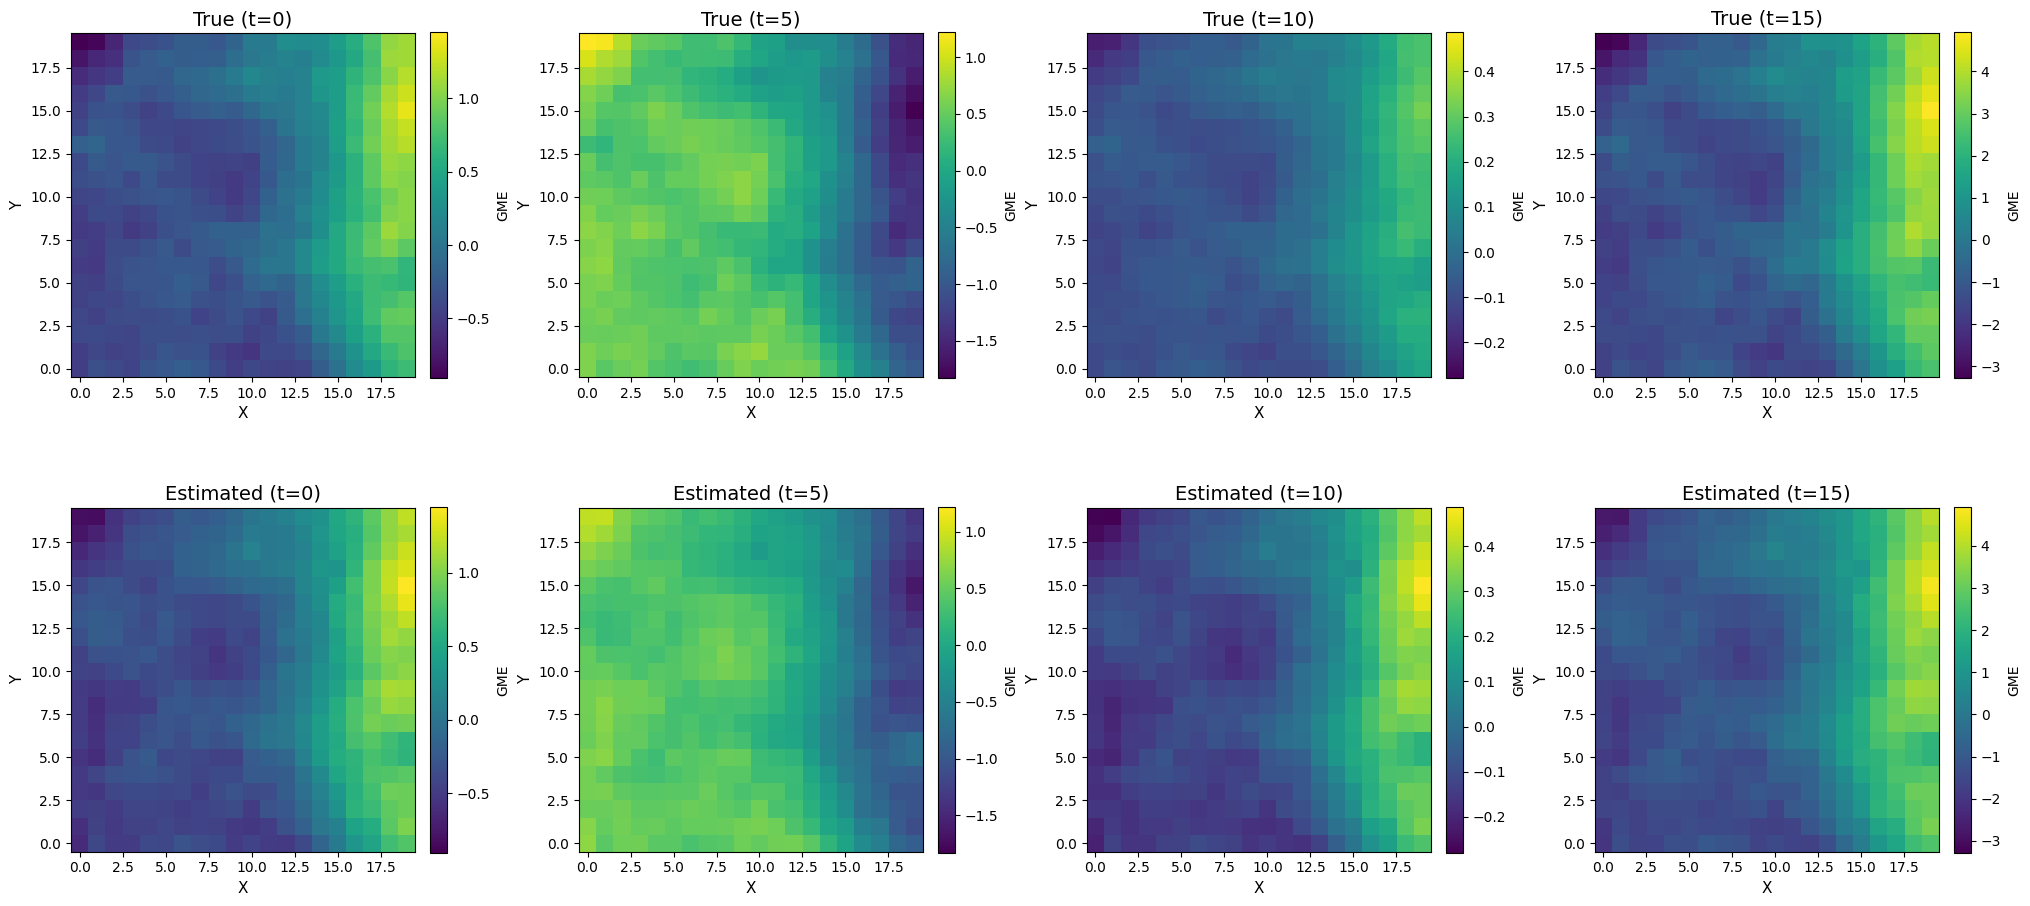


=== Metrics by Time ===
 t  Correlation     RMSE      MAE       R2
 0     0.992749 0.068892 0.055820 0.979736
 5     0.992749 0.099556 0.078938 0.976542
10     0.992749 0.060789 0.050752 0.723326
15     0.992749 0.212286 0.169234 0.985290


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
import pandas as pd


# =========================================================
# 1. Reshape
# =========================================================

nr, nc = 20, 20

u_true_map = u_true.reshape(nr, nc, -1)
u_hat_map  = u_hat.reshape(nr, nc, -1)

t_list = [0, 5, 10, 15]
n_t = len(t_list)


# =========================================================
# 2. Plot
# =========================================================

fig, axes = plt.subplots(
    2,
    n_t,
    figsize=(20, 10)
)

metrics_results = []


for i, t in enumerate(t_list):

    Z_true = u_true_map[:, :, t]
    Z_hat  = u_hat_map[:, :, t]

    # =====================================================
    # Shared color scale WITHIN each time point
    #
    # True(t) and Estimated(t) use exactly the same
    # vmin and vmax.
    #
    # Different time points are allowed to have
    # different color scales.
    # =====================================================

    vmin = min(
        Z_true.min(),
        Z_hat.min()
    )

    vmax = max(
        Z_true.max(),
        Z_hat.max()
    )


    # =====================================================
    # Metrics
    # =====================================================

    y_true = Z_true.ravel()
    y_hat  = Z_hat.ravel()

    corr = np.corrcoef(
        y_true,
        y_hat
    )[0, 1]

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_hat
        )
    )

    mae = mean_absolute_error(
        y_true,
        y_hat
    )

    r2 = r2_score(
        y_true,
        y_hat
    )

    metrics_results.append(
        [
            t,
            corr,
            rmse,
            mae,
            r2
        ]
    )


    # =====================================================
    # True GME
    # =====================================================

    ax1 = axes[0, i]

    im1 = ax1.imshow(
        Z_true,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        origin="lower",
        interpolation="nearest",
        aspect="equal"
    )

    ax1.set_title(
        f"True (t={t})",
        fontsize=14
    )

    ax1.set_xlabel(
        "X",
        fontsize=11
    )

    ax1.set_ylabel(
        "Y",
        fontsize=11
    )

    # Individual colorbar
    cbar1 = fig.colorbar(
        im1,
        ax=ax1,
        fraction=0.046,
        pad=0.04
    )

    cbar1.set_label(
        "GME",
        fontsize=10
    )


    # =====================================================
    # Estimated GME
    # =====================================================

    ax2 = axes[1, i]

    im2 = ax2.imshow(
        Z_hat,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        origin="lower",
        interpolation="nearest",
        aspect="equal"
    )

    ax2.set_title(
        f"Estimated (t={t})",
        fontsize=14
    )

    ax2.set_xlabel(
        "X",
        fontsize=11
    )

    ax2.set_ylabel(
        "Y",
        fontsize=11
    )

    # Individual colorbar
    cbar2 = fig.colorbar(
        im2,
        ax=ax2,
        fraction=0.046,
        pad=0.04
    )

    cbar2.set_label(
        "GME",
        fontsize=10
    )


# =========================================================
# 3. Layout
# =========================================================

plt.subplots_adjust(
    wspace=0.35,
    hspace=0.20,
    left=0.03,
    right=0.98,
    bottom=0.07,
    top=0.94
)


# =========================================================
# 4. Save
# =========================================================

plt.savefig(
    "/content/drive/My Drive/Moran effect/picture/Moran_effect_time_series1.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# =========================================================
# 5. Metrics output
# =========================================================

metrics_df = pd.DataFrame(
    metrics_results,
    columns=[
        "t",
        "Correlation",
        "RMSE",
        "MAE",
        "R2"
    ]
)

print("\n=== Metrics by Time ===")

print(
    metrics_df.to_string(
        index=False
    )
)


# =========================================================
# 6. Save CSV (optional)
# =========================================================

# metrics_df.to_csv(
#     "/content/drive/My Drive/Moran effect/Moran_effect_metrics.csv",
#     index=False
# )

Corr(a_hat, a_true) = 0.9914186390486596
Corr(g_hat, g_true) = 0.9992568949980857
Corr(vec(u_hat), vec(u_true)) = 0.990680123605416
RMSE(u_hat) = 0.1081144728377765
MAE(u_hat) = 0.08577829784952894
R2(u_hat) = 0.9709055370018375


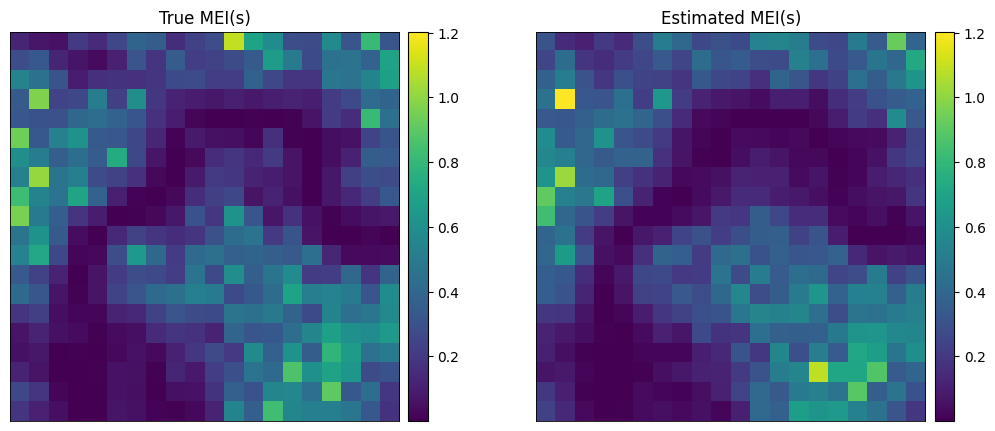

MEI Corr = 0.9344006711754046 | MEI RMSE = 0.07937215832967655 | MEI MAE = 0.053251189785891065 | MEI R2 = 0.860578240744112


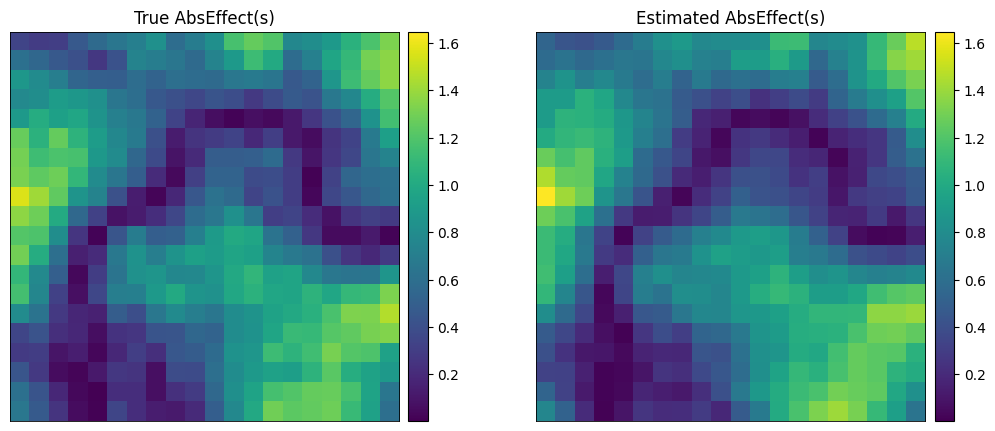

AbsEffect Corr = 0.9667007877405743 | AbsEffect RMSE = 0.0971126939636158 | AbsEffect MAE = 0.07552176894484514 | AbsEffect R2 = 0.9337681390780445


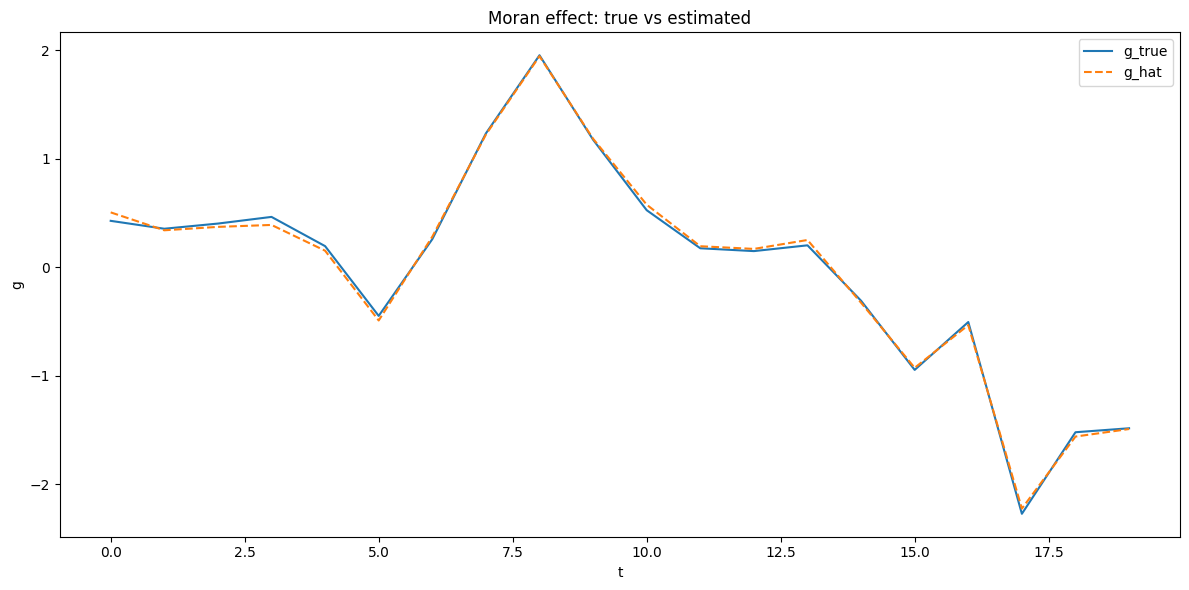

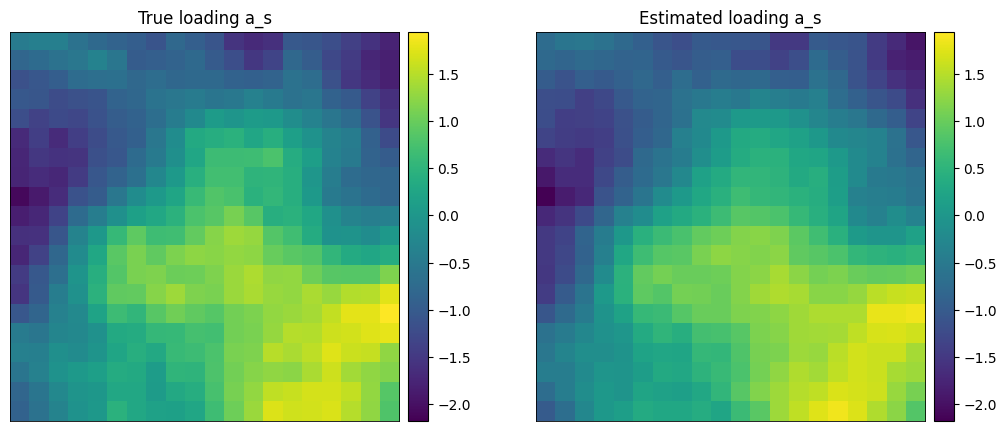

Loading Corr = 0.9914186390486596 | Loading RMSE = 0.1306326091227413 | Loading MAE = 0.1021101296680186 | Loading R2 = 0.982457914299246


REVIEWER-SPECIFIC GLOBAL/LOCAL COVARIATE EXPERIMENT

Correlation between true GME factor and omitted national signal:
0.42959514154222017


ORIGINAL MODEL VS TWO-WAY WITHIN MODEL

True local beta: 1.0000

Local covariate coefficient
Original beta_hat: 1.1817
Original bias    : 0.1817
Two-way beta_hat : 1.0256
Two-way bias     : 0.0256

Spatial loading recovery
Original Corr: 0.9863
Original R2  : -0.7045
Two-way Corr : 0.9927
Two-way R2   : 0.9855

Temporal factor recovery
Original Corr(g_hat, g_true): 0.6823
Original R2(g): 0.3646
Two-way Corr(g_hat, g_true): 0.9992
Two-way R2(g): 0.9984

Potential omitted-global-signal leakage
Corr(g_true, x_bar): 0.4296
Corr(g_original, x_bar): 0.9524
Corr(g_twoway, x_bar): 0.4432

Full GME recovery
Original Corr: 0.3201
Original RMSE: 1.4210
Original MAE : 1.0591
Original R2  : -1.1309
Two-way Corr : 0.9919
Two

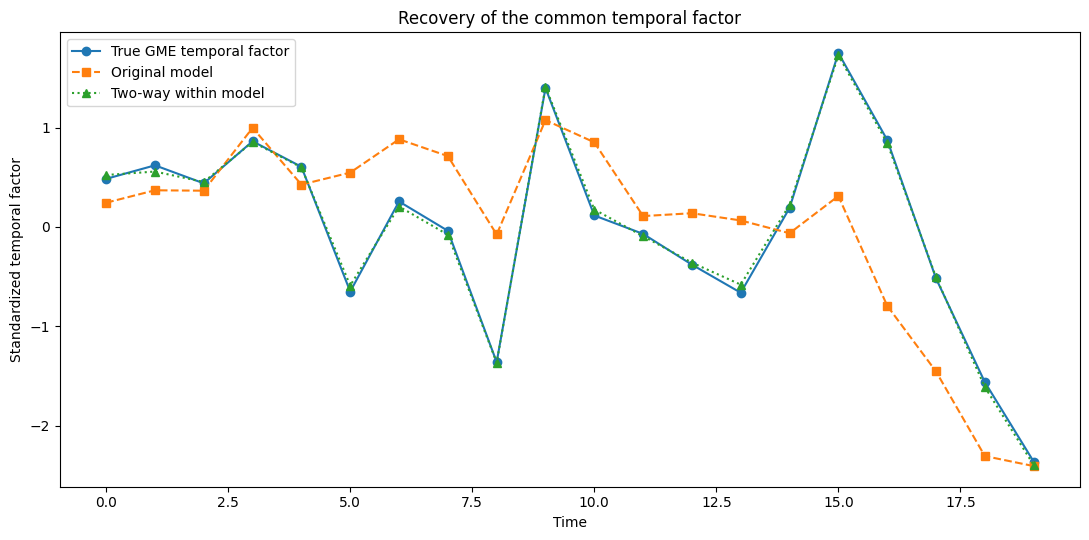

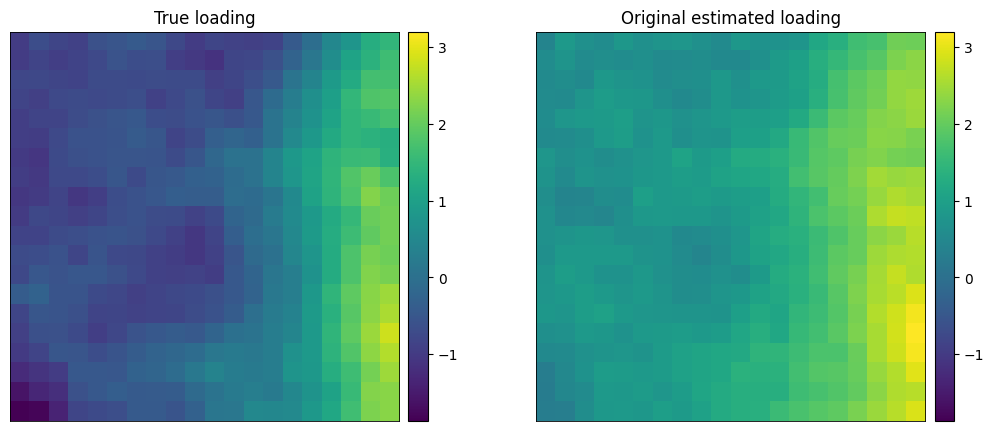

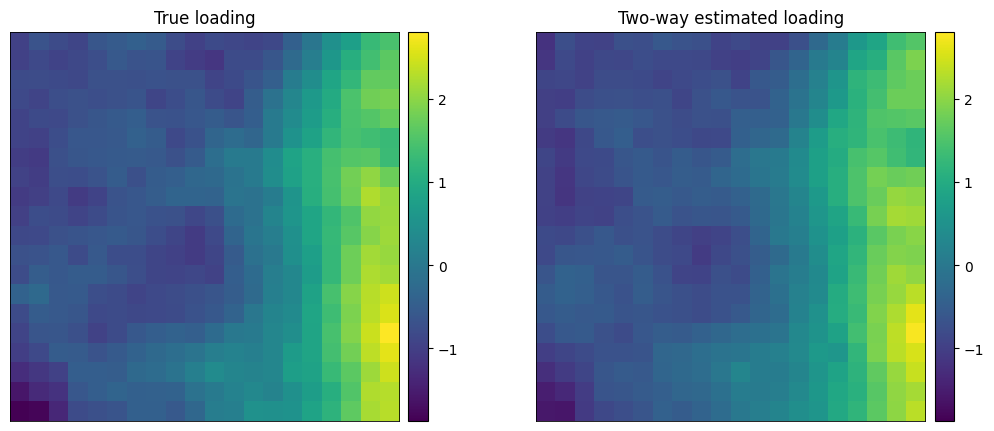

In [ ]:
"""
Spatiotemporal Synchrony Factor Model (Moran-effect type decomposition)

This script implements:

1. Simulation of spatiotemporal data containing:

   - A systematic regression component Xβ
   - A multiplicative synchrony component a(s) * g(t)
   - Optional background noise
   - Random idiosyncratic errors

2. Estimation of a separable synchrony factor:
   u(s,t) = a(s) * g(t)

   where:
   a(s)  : spatial loading (smooth over graph)
   g(t)  : temporal common shock (smooth in time)

3. Diagnostics for:

   - Recovery of spatial loading a(s)
   - Recovery of temporal factor g(t)
   - Recovery of full synchrony field u(s,t)

4. Visualization of spatial intensity measures:

   - MEI(s): variance share explained by synchrony
   - AbsEffect(s): average magnitude of synchrony effect

This framework provides a structured way to identify
Moran-type spatial synchrony that arises from common
temporal shocks modulated by spatial loading patterns.
"""

import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Tuple
import inspect

from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score,
)


# ==========================================================
# Conjugate Gradient solver wrapper
# ==========================================================

def cg_solve(
    A,
    b,
    atol=1e-10,
    rtol=1e-10,
    maxiter=5000,
):
    sig = inspect.signature(spla.cg)
    params = sig.parameters

    if "rtol" in params:
        return spla.cg(
            A,
            b,
            atol=atol,
            rtol=rtol,
            maxiter=maxiter,
        )

    elif "tol" in params:
        return spla.cg(
            A,
            b,
            atol=atol,
            tol=rtol,
            maxiter=maxiter,
        )

    else:
        return spla.cg(
            A,
            b,
            maxiter=maxiter,
        )


# ==========================================================
# Spatial graph utilities
# ==========================================================

def grid_adjacency(
    nr: int,
    nc: int,
    rook: bool = True,
) -> sp.csr_matrix:

    n = nr * nc

    rows = []
    cols = []
    data = []

    def idx(r, c):
        return r * nc + c

    directions = [
        (-1, 0),
        (1, 0),
        (0, -1),
        (0, 1),
    ]

    if not rook:
        directions += [
            (-1, -1),
            (-1, 1),
            (1, -1),
            (1, 1),
        ]

    for r in range(nr):
        for c in range(nc):

            i = idx(r, c)

            for dr, dc in directions:

                rr = r + dr
                cc = c + dc

                if (
                    0 <= rr < nr
                    and 0 <= cc < nc
                ):

                    j = idx(rr, cc)

                    rows.append(i)
                    cols.append(j)
                    data.append(1.0)

    W = sp.coo_matrix(
        (data, (rows, cols)),
        shape=(n, n),
    ).tocsr()

    W = (
        (W + W.T) > 0
    ).astype(float).tocsr()

    W.setdiag(0.0)
    W.eliminate_zeros()

    return W


def laplacian_from_W(
    W: sp.csr_matrix,
) -> sp.csr_matrix:

    d = np.asarray(
        W.sum(axis=1)
    ).ravel()

    return (
        sp.diags(
            d,
            format="csr",
        )
        - W
    ).tocsr()


# ==========================================================
# Temporal penalty: RW1 precision
# ==========================================================

def rw1_precision(
    T: int,
) -> np.ndarray:

    D = np.zeros(
        (T - 1, T)
    )

    for i in range(T - 1):

        D[i, i] = -1.0
        D[i, i + 1] = 1.0

    return D.T @ D


# ==========================================================
# Original simulation
# ==========================================================

def simulate_ar1(
    T: int,
    phi: float,
    sigma: float,
    rng: np.random.Generator,
) -> np.ndarray:

    g = np.zeros(
        T,
        dtype=float,
    )

    eps = rng.normal(
        0.0,
        sigma,
        size=T,
    )

    for t in range(1, T):

        g[t] = (
            phi * g[t - 1]
            + eps[t]
        )

    g = g - g.mean()

    g = (
        g
        / (
            g.std(ddof=1)
            + 1e-12
        )
    )

    return g


def sample_smooth_a(
    L: sp.csr_matrix,
    tau_a: float,
    rng: np.random.Generator,
) -> np.ndarray:

    n = L.shape[0]

    jitter = 1e-6

    Q = (
        tau_a * L
        + jitter
        * sp.eye(
            n,
            format="csr",
        )
    ).tocsr()

    z = rng.normal(
        size=n
    )

    a, info = cg_solve(
        Q,
        z,
        atol=1e-10,
        rtol=1e-10,
        maxiter=5000,
    )

    if info != 0:

        a = spla.spsolve(
            Q.tocsc(),
            z,
        )

    a = a - a.mean()

    a = (
        a
        / (
            a.std(ddof=1)
            + 1e-12
        )
    )

    return a


def simulate_data(
    nr: int = 20,
    nc: int = 20,
    T: int = 20,
    p: int = 3,
    phi_g: float = 0.7,
    sigma_eps: float = 1.0,
    tau_a: float = 5.0,
    include_delta: bool = False,
    seed: int = 0,
) -> Tuple[
    np.ndarray,
    np.ndarray,
    np.ndarray,
    np.ndarray,
    np.ndarray,
    sp.csr_matrix,
]:

    """
    Returns
    -------
    y          : (n, T)
    X          : (n, T, p)
    beta_true  : (p,)
    a_true     : (n,)
    g_true     : (T,)
    W          : adjacency
    """

    rng = np.random.default_rng(
        seed
    )

    n = nr * nc

    W = grid_adjacency(
        nr,
        nc,
        rook=True,
    )

    L = laplacian_from_W(
        W
    )

    X = rng.normal(
        size=(
            n,
            T,
            p,
        )
    )

    beta_true = rng.normal(
        size=p
    )

    g_true = simulate_ar1(
        T=T,
        phi=phi_g,
        sigma=1.0,
        rng=rng,
    )

    a_true = sample_smooth_a(
        L=L,
        tau_a=tau_a,
        rng=rng,
    )

    delta = np.zeros(
        (n, T),
        dtype=float,
    )

    if include_delta:

        delta = (
            0.3
            * rng.normal(
                size=(n, T)
            )
        )

    eps = rng.normal(
        0.0,
        sigma_eps,
        size=(n, T),
    )

    y = (
        np.einsum(
            "ntp,p->nt",
            X,
            beta_true,
        )
        + np.outer(
            a_true,
            g_true,
        )
        + delta
        + eps
    )

    return (
        y,
        X,
        beta_true,
        a_true,
        g_true,
        W,
    )


# ==========================================================
# ORIGINAL factor synchrony model
#
# IMPORTANT:
# This function is unchanged.
# ==========================================================

@dataclass
class FitResult:

    beta: np.ndarray
    a: np.ndarray
    g: np.ndarray
    u: np.ndarray
    resid: np.ndarray
    n_iter: int


def fit_synchrony_factor_model(
    y: np.ndarray,
    X: np.ndarray,
    W: sp.csr_matrix,
    lam_a: float = 10.0,
    lam_g: float = 10.0,
    ridge_beta: float = 1e-3,
    max_iter: int = 200,
    tol: float = 1e-6,
    seed: int = 0,
    cg_maxiter: int = 5000,
) -> FitResult:

    rng = np.random.default_rng(
        seed
    )

    n, T = y.shape
    p = X.shape[2]

    L = laplacian_from_W(
        W
    ).tocsr()

    Qt = rw1_precision(
        T
    )

    # ------------------------------------------------------
    # Ridge fit beta
    # ------------------------------------------------------

    Xv = X.reshape(
        n * T,
        p,
    )

    Yv = y.reshape(
        n * T,
        1,
    )

    XtX = (
        Xv.T @ Xv
        + ridge_beta
        * np.eye(p)
    )

    beta = np.linalg.solve(
        XtX,
        Xv.T @ Yv,
    ).ravel()

    # ------------------------------------------------------
    # Initialization
    # ------------------------------------------------------

    g = rng.normal(
        size=T
    )

    g = (
        g - g.mean()
    )

    g = (
        g
        / (
            g.std(ddof=1)
            + 1e-12
        )
    )

    a = rng.normal(
        size=n
    )

    epsI_a = 1e-8
    epsI_g = 1e-10

    # ------------------------------------------------------
    # Alternating estimation
    # ------------------------------------------------------

    for it in range(
        max_iter
    ):

        R = (
            y
            - np.einsum(
                "ntp,p->nt",
                X,
                beta,
            )
        )

        # --------------------------------------------------
        # Update a
        # --------------------------------------------------

        g2 = float(
            np.sum(
                g ** 2
            )
        )

        rhs_a = (
            R @ g
        )

        A_a = (
            g2
            * sp.eye(
                n,
                format="csr",
            )
            + lam_a * L
            + epsI_a
            * sp.eye(
                n,
                format="csr",
            )
        ).tocsr()

        a_new, info = cg_solve(
            A_a,
            rhs_a,
            atol=1e-10,
            rtol=1e-10,
            maxiter=cg_maxiter,
        )

        if info != 0:

            a_new = spla.spsolve(
                A_a.tocsc(),
                rhs_a,
            )

        # --------------------------------------------------
        # Update g
        # --------------------------------------------------

        a2 = float(
            np.sum(
                a_new ** 2
            )
        )

        rhs_g = (
            a_new[:, None]
            * R
        ).sum(
            axis=0
        )

        A_g = (
            a2
            * np.eye(T)
            + lam_g * Qt
            + epsI_g
            * np.eye(T)
        )

        g_new = np.linalg.solve(
            A_g,
            rhs_g,
        )

        # --------------------------------------------------
        # Identification
        # --------------------------------------------------

        g_new = (
            g_new
            - g_new.mean()
        )

        s = (
            g_new.std(ddof=1)
            + 1e-12
        )

        g_new = (
            g_new / s
        )

        a_new = (
            a_new * s
        )

        # --------------------------------------------------
        # Convergence
        # --------------------------------------------------

        da = (
            np.linalg.norm(
                a_new - a
            )
            /
            (
                np.linalg.norm(a)
                + 1e-12
            )
        )

        dg = (
            np.linalg.norm(
                g_new - g
            )
            /
            (
                np.linalg.norm(g)
                + 1e-12
            )
        )

        a = a_new
        g = g_new

        # --------------------------------------------------
        # Refit beta
        # --------------------------------------------------

        u_hat = np.outer(
            a,
            g,
        )

        Yv2 = (
            y - u_hat
        ).reshape(
            n * T,
            1,
        )

        beta_new = np.linalg.solve(
            XtX,
            Xv.T @ Yv2,
        ).ravel()

        db = (
            np.linalg.norm(
                beta_new - beta
            )
            /
            (
                np.linalg.norm(beta)
                + 1e-12
            )
        )

        beta = beta_new

        if max(
            da,
            dg,
            db,
        ) < tol:

            break

    u_hat = np.outer(
        a,
        g,
    )

    resid = (
        y
        - np.einsum(
            "ntp,p->nt",
            X,
            beta,
        )
        - u_hat
    )

    return FitResult(
        beta=beta,
        a=a,
        g=g,
        u=u_hat,
        resid=resid,
        n_iter=it + 1,
    )


# ==========================================================
# Utility
# ==========================================================

def corr_centered(
    x: np.ndarray,
    y: np.ndarray,
) -> float:

    x0 = (
        x - x.mean()
    )

    y0 = (
        y - y.mean()
    )

    return float(
        (x0 @ y0)
        /
        (
            np.linalg.norm(x0)
            * np.linalg.norm(y0)
            + 1e-12
        )
    )


def plot_two_panel_maps(
    A: np.ndarray,
    B: np.ndarray,
    titleA: str,
    titleB: str,
    nr: int,
    nc: int,
    shared_scale: bool = True,
    cmap: str = "viridis",
    interpolation: str = "nearest",
    savepath: str | None = None,
    dpi: int = 300,
):

    Amap = A.reshape(
        nr,
        nc,
    )

    Bmap = B.reshape(
        nr,
        nc,
    )

    if shared_scale:

        vmin = float(
            min(
                Amap.min(),
                Bmap.min(),
            )
        )

        vmax = float(
            max(
                Amap.max(),
                Bmap.max(),
            )
        )

    else:

        vmin = None
        vmax = None

    fig, ax = plt.subplots(
        1,
        2,
        figsize=(10.5, 4.2),
        constrained_layout=True,
    )

    im0 = ax[0].imshow(
        Amap,
        vmin=vmin,
        vmax=vmax,
        cmap=cmap,
        interpolation=interpolation,
    )

    ax[0].set_title(
        titleA,
        fontsize=12,
    )

    ax[0].set_xticks([])
    ax[0].set_yticks([])

    im1 = ax[1].imshow(
        Bmap,
        vmin=vmin,
        vmax=vmax,
        cmap=cmap,
        interpolation=interpolation,
    )

    ax[1].set_title(
        titleB,
        fontsize=12,
    )

    ax[1].set_xticks([])
    ax[1].set_yticks([])

    cbar0 = fig.colorbar(
        im0,
        ax=ax[0],
        fraction=0.046,
        pad=0.02,
    )

    cbar0.ax.tick_params(
        labelsize=10
    )

    cbar1 = fig.colorbar(
        im1,
        ax=ax[1],
        fraction=0.046,
        pad=0.02,
    )

    cbar1.ax.tick_params(
        labelsize=10
    )

    for a in ax:

        for spine in (
            a.spines.values()
        ):

            spine.set_linewidth(
                0.6
            )

    if savepath is not None:

        fig.savefig(
            savepath,
            dpi=dpi,
            bbox_inches="tight",
        )

    plt.show()

    return fig, ax


# ==========================================================
# NEW 1:
# Two-way within transformation
# ==========================================================

def two_way_within_y(
    y: np.ndarray,
) -> np.ndarray:

    """
    Two-way within transformation for outcome.

    Removes:
        unit-specific additive effects
        time-specific additive effects
    """

    unit_mean = y.mean(
        axis=1,
        keepdims=True,
    )

    time_mean = y.mean(
        axis=0,
        keepdims=True,
    )

    grand_mean = y.mean()

    y_tilde = (
        y
        - unit_mean
        - time_mean
        + grand_mean
    )

    return y_tilde


def two_way_within_X(
    X: np.ndarray,
) -> np.ndarray:

    """
    Two-way within transformation
    applied separately to every covariate.
    """

    unit_mean = X.mean(
        axis=1,
        keepdims=True,
    )

    time_mean = X.mean(
        axis=0,
        keepdims=True,
    )

    grand_mean = X.mean(
        axis=(0, 1),
        keepdims=True,
    )

    X_tilde = (
        X
        - unit_mean
        - time_mean
        + grand_mean
    )

    return X_tilde


# ==========================================================
# NEW 2:
# Two-way version
#
# IMPORTANT:
# Original estimator is NOT modified.
#
# We transform y and X first,
# then call the original estimator.
# ==========================================================

def fit_synchrony_factor_model_twoway(
    y: np.ndarray,
    X: np.ndarray,
    W: sp.csr_matrix,
    lam_a: float = 10.0,
    lam_g: float = 10.0,
    ridge_beta: float = 1e-3,
    max_iter: int = 200,
    tol: float = 1e-6,
    seed: int = 0,
    cg_maxiter: int = 5000,
):

    y_tilde = two_way_within_y(
        y
    )

    X_tilde = two_way_within_X(
        X
    )

    fit = fit_synchrony_factor_model(
        y=y_tilde,
        X=X_tilde,
        W=W,
        lam_a=lam_a,
        lam_g=lam_g,
        ridge_beta=ridge_beta,
        max_iter=max_iter,
        tol=tol,
        seed=seed,
        cg_maxiter=cg_maxiter,
    )

    return (
        fit,
        y_tilde,
        X_tilde,
    )


# ==========================================================
# NEW 3:
# AR(p) generator for reviewer simulation
# ==========================================================

def simulate_ar_p(
    T: int,
    phi: tuple,
    sigma: float,
    rng: np.random.Generator,
    burnin: int = 200,
) -> np.ndarray:

    """
    General AR(p) process.

    Example:
        phi=(0.6, 0.2)
    gives an AR(2).
    """

    phi = np.asarray(
        phi,
        dtype=float,
    )

    p = len(phi)

    total_T = (
        T
        + burnin
        + p
    )

    x = np.zeros(
        total_T,
        dtype=float,
    )

    eps = rng.normal(
        0.0,
        sigma,
        size=total_T,
    )

    for t in range(
        p,
        total_T,
    ):

        past = x[
            t - p:t
        ][::-1]

        x[t] = (
            phi @ past
            + eps[t]
        )

    x = x[-T:]

    x = (
        x - x.mean()
    )

    x = (
        x
        / (
            x.std(ddof=1)
            + 1e-12
        )
    )

    return x


# ==========================================================
# NEW 4:
# Row-standardize W
# only used for reviewer-specific spatial disturbance
# ==========================================================

def row_standardize_W(
    W: sp.csr_matrix,
) -> sp.csr_matrix:

    W = W.tocsr()

    d = np.asarray(
        W.sum(axis=1)
    ).ravel()

    d_inv = np.zeros_like(
        d,
        dtype=float,
    )

    mask = (
        d > 0
    )

    d_inv[mask] = (
        1.0
        / d[mask]
    )

    return (
        sp.diags(
            d_inv,
            format="csr",
        )
        @ W
    ).tocsr()


# ==========================================================
# NEW 5:
# Spatially patterned disturbance nu(s,t)
# ==========================================================

def simulate_spatial_patterned_nu(
    W: sp.csr_matrix,
    T: int,
    rho: float,
    rng: np.random.Generator,
) -> np.ndarray:

    """
    Generate spatially structured local deviations:

        nu_t =
        (I - rho W)^(-1) e_t

    A different spatial realization is generated
    at each time point.
    """

    W_row = row_standardize_W(
        W
    )

    n = W.shape[0]

    A = (
        sp.eye(
            n,
            format="csr",
        )
        - rho * W_row
    ).tocsc()

    solve_A = spla.factorized(
        A
    )

    nu = np.zeros(
        (n, T),
        dtype=float,
    )

    for t in range(T):

        e = rng.normal(
            0.0,
            1.0,
            size=n,
        )

        nu[:, t] = solve_A(
            e
        )

    # Make x_bar the actual common temporal component.
    # Remove spatial mean of nu at each t.
    nu = (
        nu
        - nu.mean(
            axis=0,
            keepdims=True,
        )
    )

    nu = (
        nu
        / (
            nu.std(ddof=1)
            + 1e-12
        )
    )

    return nu


# ==========================================================
# NEW 6:
# Reviewer-specific DGP
#
# Reviewer:
#
# x_bar(t) ~ AR(p)
# x(s,t) = x_bar(t) + nu(s,t)
#
# BOTH x_bar and x enter the TRUE DGP.
#
# But only x is supplied to the fitted model.
# ==========================================================

def simulate_reviewer_dgp(
    nr: int = 20,
    nc: int = 20,
    T: int = 20,
    p: int = 3,
    phi_global: tuple = (0.6, 0.2),
    phi_g: float = 0.7,
    rho_nu: float = 0.6,
    nu_scale: float = 0.8,
    beta_local: float = 1.0,
    gamma_global: float = 1.5,
    sigma_eps: float = 1.0,
    tau_a: float = 5.0,
    seed: int = 42,
):

    rng = np.random.default_rng(
        seed
    )

    n = nr * nc

    # ------------------------------------------------------
    # Spatial graph
    # ------------------------------------------------------

    W = grid_adjacency(
        nr,
        nc,
        rook=True,
    )

    L = laplacian_from_W(
        W
    )

    # ------------------------------------------------------
    # Reviewer:
    # national signal x_bar(t)
    # ------------------------------------------------------

    x_bar = simulate_ar_p(
        T=T,
        phi=phi_global,
        sigma=1.0,
        rng=rng,
    )

    # ------------------------------------------------------
    # Reviewer:
    # spatially patterned local disturbance
    # ------------------------------------------------------

    nu = simulate_spatial_patterned_nu(
        W=W,
        T=T,
        rho=rho_nu,
        rng=rng,
    )

    # ------------------------------------------------------
    # Local covariate
    #
    # x(s,t) = x_bar(t) + nu(s,t)
    # ------------------------------------------------------

    x_local = (
        x_bar[None, :]
        + nu_scale * nu
    )

    # ------------------------------------------------------
    # X supplied to fitted model
    # ------------------------------------------------------

    X = np.zeros(
        (n, T, p),
        dtype=float,
    )

    X[:, :, 0] = (
        x_local
    )

    if p > 1:

        X[:, :, 1:] = (
            rng.normal(
                size=(
                    n,
                    T,
                    p - 1,
                )
            )
        )

    # ------------------------------------------------------
    # True regression parameters
    # ------------------------------------------------------

    beta_true = np.zeros(
        p,
        dtype=float,
    )

    beta_true[0] = (
        beta_local
    )

    if p == 2:

        beta_true[1] = 0.5

    elif p >= 3:

        beta_true[1:] = np.linspace(
            0.5,
            -0.5,
            p - 1,
        )

    # ------------------------------------------------------
    # True GME
    # ------------------------------------------------------

    g_true = simulate_ar1(
        T=T,
        phi=phi_g,
        sigma=1.0,
        rng=rng,
    )

    a_true = sample_smooth_a(
        L=L,
        tau_a=tau_a,
        rng=rng,
    )

    u_true = np.outer(
        a_true,
        g_true,
    )

    # ------------------------------------------------------
    # Local systematic effects
    # ------------------------------------------------------

    local_effect = np.einsum(
        "ntp,p->nt",
        X,
        beta_true,
    )

    # ------------------------------------------------------
    # Omitted national effect
    #
    # This enters TRUE DGP,
    # but will NOT be supplied to fitted model.
    # ------------------------------------------------------

    global_effect = (
        gamma_global
        * x_bar[None, :]
    )

    # ------------------------------------------------------
    # Noise
    # ------------------------------------------------------

    eps = rng.normal(
        0.0,
        sigma_eps,
        size=(n, T),
    )

    # ------------------------------------------------------
    # Final outcome
    # ------------------------------------------------------

    y = (
        local_effect
        + global_effect
        + u_true
        + eps
    )

    return {
        "y": y,
        "X": X,
        "W": W,
        "beta_true": beta_true,
        "a_true": a_true,
        "g_true": g_true,
        "u_true": u_true,
        "x_bar": x_bar,
        "x_local": x_local,
        "nu": nu,
        "gamma_global": gamma_global,
    }


# ==========================================================
# NEW 7:
# Sign alignment
# ==========================================================

def align_sign(
    a_hat: np.ndarray,
    g_hat: np.ndarray,
    a_true: np.ndarray,
):

    a_hat = a_hat.copy()
    g_hat = g_hat.copy()

    if corr_centered(
        a_hat,
        a_true,
    ) < 0:

        a_hat *= -1.0
        g_hat *= -1.0

    return (
        a_hat,
        g_hat,
    )


# ==========================================================
# NEW 8:
# Comparison report
# ==========================================================

def evaluate_fit(
    name: str,
    fit: FitResult,
    sim: dict,
):

    a_hat, g_hat = align_sign(
        fit.a,
        fit.g,
        sim["a_true"],
    )

    u_hat = np.outer(
        a_hat,
        g_hat,
    )

    out = {

        "name":
            name,

        "beta_local_true":
            sim["beta_true"][0],

        "beta_local_hat":
            fit.beta[0],

        "beta_local_bias":
            fit.beta[0]
            - sim["beta_true"][0],

        "a_corr":
            corr_centered(
                a_hat,
                sim["a_true"],
            ),

        "a_r2":
            r2_score(
                sim["a_true"],
                a_hat,
            ),

        "g_corr":
            corr_centered(
                g_hat,
                sim["g_true"],
            ),

        "g_r2":
            r2_score(
                sim["g_true"],
                g_hat,
            ),

        "g_corr_with_xbar":
            corr_centered(
                g_hat,
                sim["x_bar"],
            ),

        "u_corr":
            corr_centered(
                u_hat.ravel(),
                sim["u_true"].ravel(),
            ),

        "u_rmse":
            root_mean_squared_error(
                sim["u_true"].ravel(),
                u_hat.ravel(),
            ),

        "u_mae":
            mean_absolute_error(
                sim["u_true"].ravel(),
                u_hat.ravel(),
            ),

        "u_r2":
            r2_score(
                sim["u_true"].ravel(),
                u_hat.ravel(),
            ),

        "a_hat":
            a_hat,

        "g_hat":
            g_hat,

        "u_hat":
            u_hat,
    }

    return out


# ==========================================================
# Demo run
# ==========================================================

if __name__ == "__main__":

    nr = 20
    nc = 20
    T = 20

    # ======================================================
    # ORIGINAL DEMO
    # ======================================================

    y, X, beta_true, a_true, g_true, W = simulate_data(
        nr=nr,
        nc=nc,
        T=T,
        p=3,
        phi_g=0.7,
        sigma_eps=1.0,
        tau_a=5.0,
        include_delta=False,
        seed=42,
    )

    fit = fit_synchrony_factor_model(
        y=y,
        X=X,
        W=W,
        lam_a=10.0,
        lam_g=10.0,
        ridge_beta=1e-3,
        max_iter=200,
        tol=1e-6,
        seed=0,
    )

    # ------------------------------------------------------
    # Sign alignment
    # ------------------------------------------------------

    a_hat = fit.a.copy()
    g_hat = fit.g.copy()

    if corr_centered(
        a_hat,
        a_true,
    ) < 0:

        a_hat *= -1
        g_hat *= -1

    u_true = np.outer(
        a_true,
        g_true,
    )

    u_hat = np.outer(
        a_hat,
        g_hat,
    )

    print(
        "Corr(a_hat, a_true) =",
        corr_centered(
            a_hat,
            a_true,
        ),
    )

    print(
        "Corr(g_hat, g_true) =",
        abs(
            corr_centered(
                g_hat,
                g_true,
            )
        ),
    )

    print(
        "Corr(vec(u_hat), vec(u_true)) =",
        corr_centered(
            u_hat.reshape(-1),
            u_true.reshape(-1),
        ),
    )

    print(
        "RMSE(u_hat) =",
        root_mean_squared_error(
            u_hat,
            u_true,
        ),
    )

    print(
        "MAE(u_hat) =",
        mean_absolute_error(
            u_hat,
            u_true,
        ),
    )

    print(
        "R2(u_hat) =",
        r2_score(
            u_hat,
            u_true,
        ),
    )

    # ------------------------------------------------------
    # MEI
    # ------------------------------------------------------

    var_y = np.var(
        y,
        axis=1,
        ddof=1,
    )

    mei_true = (
        np.var(
            u_true,
            axis=1,
            ddof=1,
        )
        /
        (
            var_y
            + 1e-12
        )
    )

    mei_hat = (
        np.var(
            u_hat,
            axis=1,
            ddof=1,
        )
        /
        (
            var_y
            + 1e-12
        )
    )

    plot_two_panel_maps(
        mei_true,
        mei_hat,
        titleA="True MEI(s)",
        titleB="Estimated MEI(s)",
        nr=nr,
        nc=nc,
        shared_scale=True,
    )

    print(
        "MEI Corr =",
        corr_centered(
            mei_hat,
            mei_true,
        ),
        "| MEI RMSE =",
        root_mean_squared_error(
            mei_hat,
            mei_true,
        ),
        "| MEI MAE =",
        mean_absolute_error(
            mei_hat,
            mei_true,
        ),
        "| MEI R2 =",
        r2_score(
            mei_hat,
            mei_true,
        ),
    )

    # ------------------------------------------------------
    # Absolute effect
    # ------------------------------------------------------

    abs_true = np.mean(
        np.abs(u_true),
        axis=1,
    )

    abs_hat = np.mean(
        np.abs(u_hat),
        axis=1,
    )

    plot_two_panel_maps(
        abs_true,
        abs_hat,
        titleA="True AbsEffect(s)",
        titleB="Estimated AbsEffect(s)",
        nr=nr,
        nc=nc,
        shared_scale=True,
    )

    print(
        "AbsEffect Corr =",
        corr_centered(
            abs_hat,
            abs_true,
        ),
        "| AbsEffect RMSE =",
        root_mean_squared_error(
            abs_hat,
            abs_true,
        ),
        "| AbsEffect MAE =",
        mean_absolute_error(
            abs_hat,
            abs_true,
        ),
        "| AbsEffect R2 =",
        r2_score(
            abs_hat,
            abs_true,
        ),
    )

    # ------------------------------------------------------
    # g series
    # ------------------------------------------------------

    plt.figure(
        figsize=(12, 6)
    )

    plt.plot(
        g_true,
        label="g_true",
    )

    plt.plot(
        g_hat,
        "--",
        label="g_hat",
    )

    plt.title(
        "Moran effect: true vs estimated"
    )

    plt.xlabel("t")
    plt.ylabel("g")

    plt.legend()
    plt.tight_layout()
    plt.show()

    # ------------------------------------------------------
    # Loading map
    # ------------------------------------------------------

    plot_two_panel_maps(
        a_true,
        a_hat,
        titleA="True loading a_s",
        titleB="Estimated loading a_s",
        nr=nr,
        nc=nc,
        shared_scale=True,
    )

    print(
        "Loading Corr =",
        corr_centered(
            a_hat,
            a_true,
        ),
        "| Loading RMSE =",
        root_mean_squared_error(
            a_hat,
            a_true,
        ),
        "| Loading MAE =",
        mean_absolute_error(
            a_hat,
            a_true,
        ),
        "| Loading R2 =",
        r2_score(
            a_hat,
            a_true,
        ),
    )

    # ======================================================
    # NEW:
    # REVIEWER-SPECIFIC ORIGINAL VS TWO-WAY COMPARISON
    # ======================================================

    print("\n")
    print("=" * 70)
    print(
        "REVIEWER-SPECIFIC GLOBAL/LOCAL COVARIATE EXPERIMENT"
    )
    print("=" * 70)

    sim = simulate_reviewer_dgp(
        nr=20,
        nc=20,
        T=20,
        p=3,

        # AR(2) national signal
        phi_global=(0.6, 0.2),

        # true GME factor
        phi_g=0.7,

        # spatial pattern of local deviations
        rho_nu=0.6,

        # magnitude of local deviation
        nu_scale=0.8,

        # true coefficient of local x
        beta_local=1.0,

        # omitted national effect
        gamma_global=1.5,

        sigma_eps=1.0,
        tau_a=5.0,

        seed=2026,
    )

    print(
        "\nCorrelation between true GME factor "
        "and omitted national signal:"
    )

    print(
        corr_centered(
            sim["g_true"],
            sim["x_bar"],
        )
    )

    # ======================================================
    # A. ORIGINAL MODEL
    #
    # IMPORTANT:
    # x_bar is NOT supplied.
    # ======================================================

    fit_original = fit_synchrony_factor_model(
        y=sim["y"],
        X=sim["X"],
        W=sim["W"],
        lam_a=10.0,
        lam_g=10.0,
        ridge_beta=1e-3,
        max_iter=300,
        tol=1e-7,
        seed=0,
    )

    # ======================================================
    # B. TWO-WAY MODEL
    #
    # Same original estimator.
    # Only y and X are transformed first.
    #
    # x_bar is still NOT supplied.
    # ======================================================

    (
        fit_twoway,
        y_tilde,
        X_tilde,
    ) = fit_synchrony_factor_model_twoway(
        y=sim["y"],
        X=sim["X"],
        W=sim["W"],
        lam_a=10.0,
        lam_g=10.0,
        ridge_beta=1e-3,
        max_iter=300,
        tol=1e-7,
        seed=0,
    )

    # ======================================================
    # Evaluation
    # ======================================================

    result_original = evaluate_fit(
        name="Original",
        fit=fit_original,
        sim=sim,
    )

    result_twoway = evaluate_fit(
        name="Two-way",
        fit=fit_twoway,
        sim=sim,
    )

    # ======================================================
    # Print comparison
    # ======================================================

    print("\n")
    print("=" * 70)
    print(
        "ORIGINAL MODEL VS TWO-WAY WITHIN MODEL"
    )
    print("=" * 70)

    print(
        f"\nTrue local beta: "
        f"{sim['beta_true'][0]:.4f}"
    )

    print("\nLocal covariate coefficient")

    print(
        f"Original beta_hat: "
        f"{result_original['beta_local_hat']:.4f}"
    )

    print(
        f"Original bias    : "
        f"{result_original['beta_local_bias']:.4f}"
    )

    print(
        f"Two-way beta_hat : "
        f"{result_twoway['beta_local_hat']:.4f}"
    )

    print(
        f"Two-way bias     : "
        f"{result_twoway['beta_local_bias']:.4f}"
    )

    print("\nSpatial loading recovery")

    print(
        f"Original Corr: "
        f"{result_original['a_corr']:.4f}"
    )

    print(
        f"Original R2  : "
        f"{result_original['a_r2']:.4f}"
    )

    print(
        f"Two-way Corr : "
        f"{result_twoway['a_corr']:.4f}"
    )

    print(
        f"Two-way R2   : "
        f"{result_twoway['a_r2']:.4f}"
    )

    print("\nTemporal factor recovery")

    print(
        f"Original Corr(g_hat, g_true): "
        f"{result_original['g_corr']:.4f}"
    )

    print(
        f"Original R2(g): "
        f"{result_original['g_r2']:.4f}"
    )

    print(
        f"Two-way Corr(g_hat, g_true): "
        f"{result_twoway['g_corr']:.4f}"
    )

    print(
        f"Two-way R2(g): "
        f"{result_twoway['g_r2']:.4f}"
    )

    print("\nPotential omitted-global-signal leakage")

    print(
        f"Corr(g_true, x_bar): "
        f"{corr_centered(sim['g_true'], sim['x_bar']):.4f}"
    )

    print(
        f"Corr(g_original, x_bar): "
        f"{result_original['g_corr_with_xbar']:.4f}"
    )

    print(
        f"Corr(g_twoway, x_bar): "
        f"{result_twoway['g_corr_with_xbar']:.4f}"
    )

    print("\nFull GME recovery")

    print(
        f"Original Corr: "
        f"{result_original['u_corr']:.4f}"
    )

    print(
        f"Original RMSE: "
        f"{result_original['u_rmse']:.4f}"
    )

    print(
        f"Original MAE : "
        f"{result_original['u_mae']:.4f}"
    )

    print(
        f"Original R2  : "
        f"{result_original['u_r2']:.4f}"
    )

    print(
        f"Two-way Corr : "
        f"{result_twoway['u_corr']:.4f}"
    )

    print(
        f"Two-way RMSE : "
        f"{result_twoway['u_rmse']:.4f}"
    )

    print(
        f"Two-way MAE  : "
        f"{result_twoway['u_mae']:.4f}"
    )

    print(
        f"Two-way R2   : "
        f"{result_twoway['u_r2']:.4f}"
    )

    # ======================================================
    # Figure 1:
    # True temporal factor vs both estimates
    # ======================================================

    plt.figure(
        figsize=(11, 5.5)
    )

    plt.plot(
        sim["g_true"],
        marker="o",
        label="True GME temporal factor",
    )

    plt.plot(
        result_original["g_hat"],
        marker="s",
        linestyle="--",
        label="Original model",
    )

    plt.plot(
        result_twoway["g_hat"],
        marker="^",
        linestyle=":",
        label="Two-way within model",
    )

    plt.xlabel(
        "Time"
    )

    plt.ylabel(
        "Standardized temporal factor"
    )

    plt.title(
        "Recovery of the common temporal factor"
    )

    plt.legend()

    plt.tight_layout()

    plt.show()

    # # ======================================================
    # # Figure 2:
    # # Omitted national signal vs estimated factors
    # # ======================================================

    # plt.figure(
    #     figsize=(11, 5.5)
    # )

    # plt.plot(
    #     sim["x_bar"],
    #     marker="o",
    #     label="Omitted national signal",
    # )

    # plt.plot(
    #     result_original["g_hat"],
    #     marker="s",
    #     linestyle="--",
    #     label="Original estimated factor",
    # )

    # plt.plot(
    #     result_twoway["g_hat"],
    #     marker="^",
    #     linestyle=":",
    #     label="Two-way estimated factor",
    # )

    # plt.xlabel(
    #     "Time"
    # )

    # plt.ylabel(
    #     "Standardized value"
    # )

    # plt.title(
    #     "Potential contamination by the omitted global temporal signal"
    # )

    # plt.legend()

    # plt.tight_layout()

    # plt.show()

    # ======================================================
    # Figure 3:
    # Loading maps
    # ======================================================

    plot_two_panel_maps(
        sim["a_true"],
        result_original["a_hat"],
        titleA="True loading",
        titleB="Original estimated loading",
        nr=20,
        nc=20,
        shared_scale=True,
    )

    plot_two_panel_maps(
        sim["a_true"],
        result_twoway["a_hat"],
        titleA="True loading",
        titleB="Two-way estimated loading",
        nr=20,
        nc=20,
        shared_scale=True,
    )